In [1]:
%matplotlib widget

In [2]:
%%capture
from ocelot import *
from ocelot.gui import *
import matplotlib.pyplot as plt
import numpy as np
from felarc.simple_tba import get_isochronous_arc_dispersion_condition, get_quad_strengths, ArcDefinition, make_arc
from felarc.plot import plot_optics, plot_r56_full
from felarc.t20 import ARC_ANGLE_RAD

The T20 arc comprises a $>6°$ bend.  We start with the simplest isochronous lattice: three identical dipoles, with a total bending angle equal to the 6° we are after.  We also choose a 3m dipole on the basis that in Nina's design we covered the $6°$ in 9m of dipole.

In [3]:
DIPOLE_ANGLE = ARC_ANGLE_RAD / 3
DIPOLE_LENGTH = 3
dx, dxp = get_isochronous_arc_dispersion_condition(dipole_length=DIPOLE_LENGTH, dipole_angle=DIPOLE_ANGLE)

In [4]:
print(dx, dxp)

-0.0261740907458337 -0.01746038085732892


In [5]:
ad = ArcDefinition(dipole_length=DIPOLE_LENGTH, dipole_angle=DIPOLE_ANGLE, l1=1., l2=1, l3=2., qlength=1., k11=1, k12=-1)
mlat = make_arc(ad)
k11, k12 = get_quad_strengths(ad)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 103
         Function evaluations: 196
[ 0.87458172 -1.33585803]


In [6]:
print(k11, k12)
ad.k11 = k11
ad.k12 = k12
print(ad)
mlat, markers = make_arc(ad)

0.8745817213073852 -1.335858028843437
ArcDefinition(dipole_length=3, dipole_angle=0.03490658503988659, l1=1.0, l2=1, l3=2.0, qlength=1.0, k11=np.float64(0.8745817213073852), k12=np.float64(-1.335858028843437))


In [10]:
twiss0 = Twiss(beta_x=20, beta_y=100)
twisses = twiss(mlat, twiss0)
dx_actual, dxp_actual = twisses[-1].Dx, twisses[-1].Dxp
print(f"Required Dx: {dx}, Actual Dx: {dxp}")
print(f"Fitted Dx: {dx_actual}, Actual Dx: {dxp_actual}")

Required Dx: -0.0261740907458337, Actual Dx: -0.01746038085732892
Fitted Dx: 3.577071652077768e-08, Actual Dx: 2.0757946493643598e-08


(<Figure size 1280x480 with 5 Axes>,
 array([<Axes: >, <Axes: ylabel='$D_x$ / m'>,
        <Axes: ylabel='$\\rho^{-1}\\,/\\,\\mathrm{m}^{-1}$'>,
        <Axes: ylabel='$D\\rho^{-1}$'>,
        <Axes: xlabel='$s$ / m', ylabel='$R_{56}$ / mm'>], dtype=object))

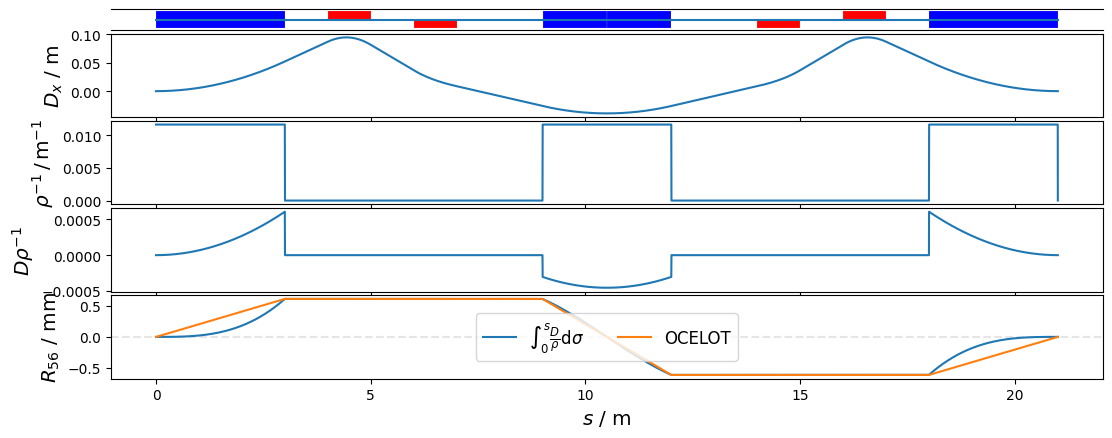

In [12]:
mlat_full, markers = make_arc(ad)
plot_r56_full(twiss0, mlat_full)

Now checking the transverse beam optics, we see that although the dispersion has a waist in the middle dipole and that $R_{56}=0$ for the arc, the transverse beam optics diverge considerably:


(<Figure size 1280x480 with 4 Axes>,
 array([<Axes: >, <Axes: ylabel='$\\beta$ / m'>, <Axes: ylabel='$D$ / m'>,
        <Axes: xlabel='$s$ / m', ylabel="$D'$ / rad">], dtype=object))

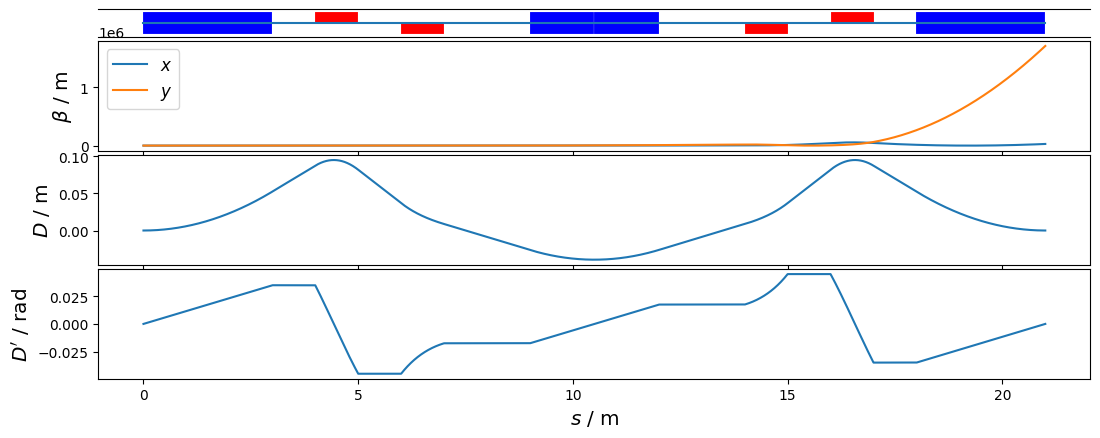

In [14]:
plot_optics(twiss0, mlat)

So we need a beta function waist (i.e. $\alpha_x = \alpha_y = 0$) in the middle of the arc, too.  To do this, we match with some additional constraints.

In [22]:
from felarc.matching import match_twiss
from copy import deepcopy
def get_quad_strengths_new(ad: ArcDefinition) -> ArcDefinition:
    # The book suggests varying a drift and a quad strength to match the two conditions
    # But here instead I'm going to use two quads to reach the condition.
    # mlat = make_arc_to_inner_dipole_start(ad)
    mlat, markers = make_arc(ad)
    dx, dxp = get_isochronous_arc_dispersion_condition(ad.dipole_length, ad.dipole_angle)

    twiss0 = Twiss(beta_x=20, beta_y=10)
    result = deepcopy(ad)
    # Get the quads from the lattice.
    quads = [ele for ele in mlat.sequence if isinstance(ele, Quadrupole)][:2]
    quads[0].k1 = -1
    quads[1].k1 = 1
    quads = [ele for ele in mlat.sequence if isinstance(ele, Quadrupole)][:2]
    drifts = [ele for ele in mlat.sequence if isinstance(ele, Drift)][:2]
    knobs = quads + drifts
    result = match_twiss(
        mlat,
        verbose=True,
        max_iter=1_000_000,
        constr={markers.middle_dipole_start: {"Dx": dx, "Dxp": dxp},
               markers.middle: {"alpha_x": 0.0}
               },
        vars=knobs,
        tw=twiss0,
    )
    print(result)
    return result # type: ignore
k1, k2, l1, l2 = get_quad_strengths_new(ad)


initial value: x =  [-1, 1, 1.0, 1]
iteration error: 1343073888.8463068
iteration error: 1458970375.0361767
iteration error: 2017250343.6494515
iteration error: 1346045669.604022
iteration error: 1549542625.7116683
iteration error: 945331826.123155
iteration error: 578801686.407854
iteration error: 810621924.2502896
iteration error: 647563607.3474092
iteration error: 440384688.07722294
iteration error: 196194034.88520667
iteration error: 117025811.70513235
iteration error: 2386811.2994791428
iteration error: 22187448.36826798
iteration error: 3582024.2074568095
iteration error: 31594822.77161643
iteration error: 34816899.50758895
iteration error: 27422760.076706775
iteration error: 81352913.96659389
iteration error: 15924387.806165772
iteration error: 66453895.42119322
iteration error: 11013956.949672792
iteration error: 35461555.993097425
iteration error: 1505971.5430533595
iteration error: 14040632.450113568
iteration error: 2183601.055105449
iteration error: 30097697.26358258
iterat

In [ ]:
plot_opt_func(tws=twiss0, 